# SwinV2-Small — Two-Phase Training (Best Configuration)

**EEEM068 Applied Machine Learning — Group Coursework**

**Model:** `swinv2_small_window8_256` pre-trained on ImageNet-22k, fine-tuned for 5-class DR grading.

**Strategy:** Two-phase training — freeze backbone, train head only (Phase 1), then unfreeze all layers with layer-wise LR and warmup+cosine schedule (Phase 2).

| Setting | Value |
|---|---|
| Phase 1 epochs | 12 (head only) |
| Phase 2 epochs | 25 (full model) |
| Phase 2 head LR | 1e-4 |
| Phase 2 backbone LR | 1e-5 (0.1×) |
| Loss | FocalLoss (γ=2, α=None) |
| Sampler | WeightedRandomSampler + Smart Downsampling (√N cap) |
| Scheduler | 3-epoch warmup → cosine decay |
| Test QWK | **0.666** |

## 1. Imports

In [1]:
import os
import random
from pathlib import Path

import timm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.optim.lr_scheduler import SequentialLR, LinearLR, CosineAnnealingLR
from torchvision import transforms
from sklearn.metrics import (
    classification_report, cohen_kappa_score, confusion_matrix,
    f1_score, accuracy_score, precision_score, recall_score,
)

print(f'PyTorch : {torch.__version__}')
print(f'timm    : {timm.__version__}')
print(f'CUDA    : {torch.cuda.is_available()}')

/scratch/AML_G14_CW/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch : 2.11.0+cu130
timm    : 1.0.26
CUDA    : True


## 2. Configuration

In [2]:
# ── Paths ──────────────────────────────────────────────────────────────────────
NOTEBOOK_DIR    = Path().resolve()
ROOT            = NOTEBOOK_DIR.parent

DATA_ROOT       = ROOT / 'data' / 'diabetic-retinopathy-detection'
TRAIN_DIR       = DATA_ROOT / 'train_proc'
VAL_DIR         = DATA_ROOT / 'val_proc'
TEST_DIR        = DATA_ROOT / 'test_labels_proc'
TRAIN_CSV       = DATA_ROOT / 'train_split.csv'
VAL_CSV         = DATA_ROOT / 'val_split.csv'
TEST_CSV        = DATA_ROOT / 'test_split.csv'

OUT_DIR         = ROOT / 'outputs' / 'swinv2_twophase_best'
CKPT_DIR        = OUT_DIR / 'checkpoints'
FIG_DIR         = OUT_DIR / 'figures'
for d in (CKPT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

CKPT_P1   = CKPT_DIR / 'phase1_best.pt'
CKPT_BEST = CKPT_DIR / 'phase2_best.pt'

# ── Offline weights (Surrey HPC) ──────────────────────────────────────────────
# Download once on the LOGIN NODE:
#   wget -O /scratch/AML_G14_CW/weights/swinv2_small.safetensors \
#     https://huggingface.co/timm/swinv2_small_window8_256.ms_in1k/resolve/main/model.safetensors
WEIGHTS_PATH = ROOT / 'weights' / 'swinv2_small.safetensors'

# ── Model ─────────────────────────────────────────────────────────────────────
MODEL_NAME  = 'swinv2_small_window8_256'
NUM_CLASSES = 5
CLASS_NAMES = ['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferative']
IMAGE_SIZE  = 256
SWIN_MEAN   = (0.485, 0.456, 0.406)
SWIN_STD    = (0.229, 0.224, 0.225)
DROPOUT     = 0.3

# ── Reproducibility ───────────────────────────────────────────────────────────
SEED = 42

# ── DataLoader ────────────────────────────────────────────────────────────────
BATCH_SIZE   = 16
NUM_WORKERS  = 4

# ── Two-phase hyperparameters (best configuration — QWK 0.666) ────────────────
PHASE1_EPOCHS   = 5        # head-only training
PHASE2_EPOCHS   = 25        # full model fine-tuning
PHASE1_HEAD_LR  = 1e-4      # head LR during Phase 1
PHASE2_HEAD_LR  = 1e-4      # head LR during Phase 2
PHASE2_BACK_LR  = 1e-5      # backbone LR during Phase 2 (0.1× head)
WARMUP_EPOCHS   = 3         # linear warmup before cosine decay
WEIGHT_DECAY    = 3e-2
GRAD_CLIP       = 1.0
PATIENCE        = 6         # early stopping patience

print('Configuration loaded ✓')

Configuration loaded ✓


In [3]:
# ── Seed + device ─────────────────────────────────────────────────────────────
def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
device  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_amp = device.type == 'cuda'
print('Device:', device)
if device.type == 'cuda':
    print(f'GPU   : {torch.cuda.get_device_name(0)}')
    print(f'VRAM  : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')

Device: cuda
GPU   : NVIDIA RTX A4000
VRAM  : 16.7 GB


## 3. Load Data

In [4]:
train_df = pd.read_csv(TRAIN_CSV)
val_df   = pd.read_csv(VAL_CSV)
test_df  = pd.read_csv(TEST_CSV)

print(f'Train : {len(train_df):,} images  (dir: train_proc/)')
print(f'Val   : {len(val_df):,} images   (dir: val_proc/)')
print(f'Test  : {len(test_df):,} images   (dir: test_labels_proc/)')
print()
print(f'{"Grade":<6} {"Name":<18} {"Train":>7} {"Val":>7} {"Test":>7}')
print('-' * 52)
for g, name in enumerate(CLASS_NAMES):
    t = (train_df['level'] == g).sum()
    v = (val_df['level']   == g).sum()
    s = (test_df['level']  == g).sum()
    print(f'  {g}    {name:<18} {t:>6,}  {v:>6,}  {s:>6,}')
print()
max_c = train_df['level'].value_counts().max()
min_c = train_df['level'].value_counts().min()
print(f'Imbalance ratio (train): {max_c/min_c:.1f}×')

Train : 24,588 images  (dir: train_proc/)
Val   : 5,269 images   (dir: val_proc/)
Test  : 5,269 images   (dir: test_labels_proc/)

Grade  Name                 Train     Val    Test
----------------------------------------------------
  0    No DR              18,067   3,871   3,872
  1    Mild                1,710     367     366
  2    Moderate            3,704     794     794
  3    Severe                611     131     131
  4    Proliferative         496     106     106

Imbalance ratio (train): 36.4×


## 4. Dataset, Transforms, Downsampling & Sampler

In [5]:
class DRDataset(Dataset):
    """Fundus image dataset.
    Images loaded from preprocessed directories (13-stage pipeline already applied).
    Only augmentation transforms applied here — no on-the-fly preprocessing.
    """
    def __init__(self, df: pd.DataFrame, data_dir: Path, transform=None):
        self.df        = df.reset_index(drop=True)
        self.data_dir  = Path(data_dir)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int):
        row   = self.df.iloc[idx]
        image = Image.open(self.data_dir / f"{row['image']}.jpeg").convert('RGB')
        label = int(row['level'])
        if self.transform is not None:
            image = self.transform(image)
        return image, label


# ── Enhanced training transform ────────────────────────────────────────────────
# Augmentations justified for retinal imaging:
#   H/V flip     → fundus cameras capture either eye, no canonical orientation
#   Rotation     → camera orientation varies across imaging sites
#   ColorJitter  → variable imaging conditions across hospitals
#   Affine       → mild geometric variation for fundus shape
#   RandomErasing → forces model to attend to multiple lesion regions
train_transform = transforms.Compose([
    transforms.Resize(int(IMAGE_SIZE * 1.14)),
    transforms.RandomCrop(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomApply([transforms.RandomRotation(degrees=30)], p=0.5),
    transforms.RandomApply([
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05)
    ], p=0.4),
    transforms.RandomApply([
        transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05))
    ], p=0.3),
    transforms.ToTensor(),
    transforms.Normalize(SWIN_MEAN, SWIN_STD),
    transforms.RandomErasing(p=0.2),
])

val_transform = transforms.Compose([
    transforms.Resize(int(IMAGE_SIZE * 1.05)),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(SWIN_MEAN, SWIN_STD),
])

print('Transforms defined ✓')

Transforms defined ✓


In [6]:
counts_raw = train_df['level'].value_counts().to_dict()
max_count  = max(counts_raw.values())

GRADE0_CAP = 1710  # matches Mild (Grade 1) count — equalises the two boundary classes

print("Class counts before downsampling:")
for g, name in enumerate(CLASS_NAMES):
    print(f"  Grade {g} ({name:<15}): {counts_raw.get(g, 0):>6,}")
print(f"\nGrade 0 cap: {GRADE0_CAP:,}  (Grades 1–4 unchanged)")

# Only Grade 0 is downsampled; all minority classes stay 100% intact
sampled_parts = []
for grade in range(NUM_CLASSES):
    grade_df = train_df[train_df['level'] == grade]
    if grade == 0 and len(grade_df) > GRADE0_CAP:
        grade_df = grade_df.sample(n=GRADE0_CAP, random_state=SEED)
    sampled_parts.append(grade_df)

train_df_ds = pd.concat(sampled_parts).sample(frac=1, random_state=SEED).reset_index(drop=True)

counts_after = train_df_ds['level'].value_counts().sort_index().to_dict()
print("\nClass counts after downsampling:")
for g, name in enumerate(CLASS_NAMES):
    orig    = counts_raw.get(g, 0)
    after   = counts_after.get(g, 0)
    dropped = orig - after
    flag    = f"  (−{dropped:,} removed)" if dropped > 0 else "  (unchanged)"
    print(f"  Grade {g} ({name:<15}): {after:>6,}{flag}")

max_after = max(counts_after.values())
min_after = min(counts_after.values())
print(f"\nImbalance ratio before : {max_count / min(counts_raw.values()):.1f}×")
print(f"Imbalance ratio after  : {max_after / min_after:.1f}×")
print(f"Total training samples : {len(train_df_ds):,}  (was {len(train_df):,})")

# ── Datasets ──────────────────────────────────────────────────────────────────
train_ds = DRDataset(train_df_ds, TRAIN_DIR, transform=train_transform)
val_ds   = DRDataset(val_df,      VAL_DIR,   transform=val_transform)
test_ds  = DRDataset(test_df,     TEST_DIR,  transform=val_transform)

# ── DataLoaders — shuffle=True, no WRS (class balance via alpha in OrdinalFocalLoss)
train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True,
    drop_last=True, persistent_workers=NUM_WORKERS > 0,
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
    persistent_workers=NUM_WORKERS > 0,
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
    persistent_workers=NUM_WORKERS > 0,
)

print(f'\nTrain batches : {len(train_loader)}')
print(f'Val batches   : {len(val_loader)}')
print(f'Test batches  : {len(test_loader)}')
print(f'Sampler       : Grade-0 hard cap ({GRADE0_CAP:,}) + shuffle — no WRS ✓')


Class counts before downsampling:
  Grade 0 (No DR          ): 18,067
  Grade 1 (Mild           ):  1,710
  Grade 2 (Moderate       ):  3,704
  Grade 3 (Severe         ):    611
  Grade 4 (Proliferative  ):    496

Grade 0 cap: 1,710  (Grades 1–4 unchanged)

Class counts after downsampling:
  Grade 0 (No DR          ):  1,710  (−16,357 removed)
  Grade 1 (Mild           ):  1,710  (unchanged)
  Grade 2 (Moderate       ):  3,704  (unchanged)
  Grade 3 (Severe         ):    611  (unchanged)
  Grade 4 (Proliferative  ):    496  (unchanged)

Imbalance ratio before : 36.4×
Imbalance ratio after  : 7.5×
Total training samples : 8,231  (was 24,588)

Train batches : 514
Val batches   : 330
Test batches  : 330
Sampler       : Grade-0 hard cap (1,710) + shuffle — no WRS ✓


## 5. Model

`swinv2_small_window8_256` — pre-trained on ImageNet-22k (11,821 classes).

**Why SwinV2-Small:**
- Hierarchical windowed attention captures local retinal lesion patterns (microaneurysms, haemorrhages) better than global attention (ViT)
- Post-norm + scaled cosine attention → stable fine-tuning, no activation collapse
- 50M params fits comfortably on 16 GB GPU at batch=16

In [7]:
def _load_swin_weights(backbone: nn.Module, weights_path: str) -> None:
    """Load local .safetensors with strict=False.
    Ignores: original ImageNet head keys, cached attn_mask buffers.
    All feature extraction weights are loaded.
    """
    from timm.models._helpers import load_checkpoint
    result = load_checkpoint(backbone, weights_path, strict=False)
    n_head = len([k for k in result.missing_keys    if 'custom_head' in k])
    n_skip = len([k for k in result.unexpected_keys if 'head.fc' in k or 'attn_mask' in k])
    print(f'  Weights loaded — head keys (random init): {n_head}, old keys ignored: {n_skip}')


def build_swin_model(pretrained: bool = True) -> nn.Module:
    """Build SwinV2-Small with a custom 5-class head.

    Custom head is necessary because timm's SwinV2 forward_features()
    returns (B, tokens, C) — a 3D tensor that breaks CrossEntropyLoss.
    Using backbone.forward (which includes GAP) returns (B, 768).
    """
    backbone = timm.create_model(
        MODEL_NAME, pretrained=False, num_classes=0, global_pool='avg')
    feat_dim = backbone.num_features  # 768

    backbone.custom_head = nn.Sequential(
        nn.LayerNorm(feat_dim),
        nn.Dropout(p=DROPOUT),
        nn.Linear(feat_dim, NUM_CLASSES),
    )
    _base = backbone.forward
    backbone.forward = lambda x: backbone.custom_head(_base(x))

    wp = Path(str(WEIGHTS_PATH)) if WEIGHTS_PATH else None
    if wp and wp.exists():
        print(f'Loading local weights: {wp.name}')
        _load_swin_weights(backbone, str(wp))
    elif pretrained:
        try:
            print('Downloading pretrained weights from HuggingFace...')
            tmp    = timm.create_model(MODEL_NAME, pretrained=True, num_classes=0, global_pool='avg')
            own_sd = backbone.state_dict()
            src_sd = {k: v for k, v in tmp.state_dict().items()
                      if k in own_sd and 'custom_head' not in k}
            own_sd.update(src_sd)
            backbone.load_state_dict(own_sd, strict=False)
            del tmp
            print('Pretrained weights loaded ✓')
        except Exception as e:
            print(f'Download failed: {e}')
            raise
    else:
        print('Random initialisation.')

    total = sum(p.numel() for p in backbone.parameters()) / 1e6
    print(f'SwinV2-Small | {total:.1f}M params')
    return backbone

## 6. Loss Function

**FocalLoss(alpha=None, gamma=2.0)**
- `alpha=None` — class balance handled by WRS at the data level. Adding alpha weights on top of WRS double-penalises Grade 0, collapsing its recall to zero.
- `gamma=2.0` — down-weights easy well-classified examples, focuses gradient on hard minority-class cases.

In [8]:
class FocalLoss(nn.Module):
    """Focal Loss — gamma-only variant (no alpha class weights).

    WRS already handles class imbalance at the data level.
    gamma=2.0 focuses learning on hard examples without suppressing Grade 0.
    """
    def __init__(self, gamma: float = 2.0):
        super().__init__()
        self.gamma = gamma

    def forward(self, logits: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
        ce = F.cross_entropy(logits, target, reduction='none')
        pt = torch.exp(-ce)
        return ((1.0 - pt) ** self.gamma * ce).mean()


criterion = FocalLoss(gamma=2.0)
print(f'Loss: FocalLoss(gamma={criterion.gamma}, alpha=None)')

Loss: FocalLoss(gamma=2.0, alpha=None)


## 7. Training Loop

In [9]:
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)


def run_epoch(model, loader, train_mode: bool):
    """Single train or eval pass.
    Returns (avg_loss, all_labels, all_preds, quadratic_kappa).
    """
    model.train(train_mode)
    total_loss, total = 0.0, 0
    all_preds, all_labels = [], []

    for images, labels in tqdm(loader, leave=False,
                               desc='train' if train_mode else 'val  '):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast(device_type='cuda', enabled=use_amp):
            logits = model(images)
            loss   = criterion(logits, labels)

        if train_mode:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            scaler.step(optimizer)
            scaler.update()

        total_loss += loss.item() * labels.size(0)
        total      += labels.size(0)
        all_preds.extend(logits.argmax(dim=1).cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

    avg_loss = total_loss / total
    kappa    = cohen_kappa_score(all_labels, all_preds, weights='quadratic')
    return avg_loss, all_labels, all_preds, kappa


print('run_epoch defined ✓')

run_epoch defined ✓


## 8. Phase 1 — Freeze Backbone, Train Head Only

Backbone is frozen. Only the custom head (LayerNorm → Dropout → Linear) is trained.
This lets the head learn a reasonable 5-class mapping before the full model is unfrozen,
preventing catastrophic forgetting of ImageNet-22k pre-trained features.

In [10]:
set_seed()
model = build_swin_model(pretrained=True).to(device)

# Freeze everything except the classification head
for name, param in model.named_parameters():
    param.requires_grad = ('custom_head' in name)

trainable_p1 = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Phase 1: {trainable_p1:,} trainable params (custom_head only)')

optimizer   = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=PHASE1_HEAD_LR, weight_decay=WEIGHT_DECAY,
)
scheduler_p1 = CosineAnnealingLR(optimizer, T_max=PHASE1_EPOCHS)

# ── Phase 1 training loop ─────────────────────────────────────────────────────
history_p1     = {'train_loss': [], 'val_loss': [], 'train_kappa': [], 'val_kappa': []}
p1_best_kappa  = -1.0
p1_patience    = PATIENCE

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr κ':>8} {'Val Loss':>10} {'Val κ':>8}")
print('─' * 52)

for epoch in range(1, PHASE1_EPOCHS + 1):
    tr_loss, _, _, tr_kappa = run_epoch(model, train_loader, train_mode=True)
    vl_loss, _, _, vl_kappa = run_epoch(model, val_loader,   train_mode=False)
    scheduler_p1.step()

    history_p1['train_loss'].append(tr_loss)
    history_p1['val_loss'].append(vl_loss)
    history_p1['train_kappa'].append(tr_kappa)
    history_p1['val_kappa'].append(vl_kappa)

    marker = ''
    if vl_kappa > p1_best_kappa:
        p1_best_kappa = vl_kappa
        p1_patience   = PATIENCE
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_kappa': vl_kappa, 'val_loss': vl_loss}, CKPT_P1)
        marker = '  ★'
    else:
        p1_patience -= 1

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_kappa:>8.4f} {vl_loss:>10.4f} {vl_kappa:>8.4f}{marker}')

    if p1_patience <= 0:
        print(f'Early stopping at epoch {epoch}.')
        break

print(f'\nPhase 1 complete. Best val κ = {p1_best_kappa:.4f}')

Pretrained weights loaded ✓
SwinV2-Small | 49.0M params
Phase 1: 5,381 trainable params (custom_head only)
Epoch       Tr Loss     Tr κ   Val Loss    Val κ
────────────────────────────────────────────────────


1            0.8526   0.1190     0.7060   0.0528  ★


2            0.7694   0.1932     0.7085   0.1421  ★


3            0.7303   0.2731     0.7062   0.1031


4            0.7156   0.2762     0.7132   0.1027


5            0.7061   0.3000     0.7273   0.0849

Phase 1 complete. Best val κ = 0.1421


## 9. Phase 2 — Unfreeze All, Layer-wise LR, Warmup + Cosine

All layers unfrozen. Layer-wise LR: backbone gets 1e-5 (0.1× head) to preserve
pre-trained features. Warmup for 3 epochs prevents a sudden LR spike at the start
of Phase 2.

In [11]:
# Unfreeze all parameters
for param in model.parameters():
    param.requires_grad = True
print(f'Phase 2: {sum(p.numel() for p in model.parameters()):,} trainable params (all)')

# Load Phase 1 best checkpoint as starting point
ckpt_p1 = torch.load(CKPT_P1, map_location=device, weights_only=False)
model.load_state_dict(ckpt_p1['model_state'])
print(f'Loaded Phase 1 best (epoch {ckpt_p1["epoch"]}, κ={ckpt_p1["val_kappa"]:.4f})')

# Layer-wise LR: backbone 1e-5, head 1e-4
backbone_params = [p for n, p in model.named_parameters() if 'custom_head' not in n]
head_params     = [p for n, p in model.named_parameters() if 'custom_head' in n]
optimizer = torch.optim.AdamW(
    [{'params': backbone_params, 'lr': PHASE2_BACK_LR},
     {'params': head_params,     'lr': PHASE2_HEAD_LR}],
    weight_decay=WEIGHT_DECAY,
)
print(f'Layer-wise LR: backbone={PHASE2_BACK_LR:.0e}  head={PHASE2_HEAD_LR:.0e}')

# 3-epoch linear warmup → cosine decay
warmup_sched  = LinearLR(optimizer, start_factor=0.1, total_iters=WARMUP_EPOCHS)
cosine_sched  = CosineAnnealingLR(optimizer, T_max=PHASE2_EPOCHS - WARMUP_EPOCHS)
scheduler_p2  = SequentialLR(optimizer, [warmup_sched, cosine_sched],
                              milestones=[WARMUP_EPOCHS])
print(f'Scheduler: {WARMUP_EPOCHS}-epoch warmup → cosine decay')

# ── Phase 2 training loop ─────────────────────────────────────────────────────
history_p2     = {'train_loss': [], 'val_loss': [], 'train_kappa': [], 'val_kappa': []}
p2_best_kappa  = -1.0
p2_patience    = PATIENCE

print(f"\n{'Epoch':<8} {'Tr Loss':>10} {'Tr κ':>8} {'Val Loss':>10} {'Val κ':>8}")
print('─' * 52)

for epoch in range(1, PHASE2_EPOCHS + 1):
    tr_loss, _, _, tr_kappa = run_epoch(model, train_loader, train_mode=True)
    vl_loss, _, _, vl_kappa = run_epoch(model, val_loader,   train_mode=False)
    scheduler_p2.step()

    history_p2['train_loss'].append(tr_loss)
    history_p2['val_loss'].append(vl_loss)
    history_p2['train_kappa'].append(tr_kappa)
    history_p2['val_kappa'].append(vl_kappa)

    marker = ''
    if vl_kappa > p2_best_kappa:
        p2_best_kappa = vl_kappa
        p2_patience   = PATIENCE
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_kappa': vl_kappa, 'val_loss': vl_loss}, CKPT_BEST)
        marker = '  ★'
    else:
        p2_patience -= 1

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_kappa:>8.4f} {vl_loss:>10.4f} {vl_kappa:>8.4f}{marker}')

    if p2_patience <= 0:
        print(f'Early stopping at epoch {epoch}.')
        break

print(f'\nPhase 2 complete. Best val κ = {p2_best_kappa:.4f}')

Phase 2: 48,964,799 trainable params (all)
Loaded Phase 1 best (epoch 2, κ=0.1421)
Layer-wise LR: backbone=1e-05  head=1e-04
Scheduler: 3-epoch warmup → cosine decay

Epoch       Tr Loss     Tr κ   Val Loss    Val κ
────────────────────────────────────────────────────


1            0.7206   0.2785     0.7893   0.1226  ★


2            0.6698   0.3877     0.6913   0.2132  ★


3            0.6235   0.4441     0.5354   0.4058  ★


4            0.5807   0.5025     0.7263   0.2602


...

16           0.3987   0.6826     0.6025   0.4130


17           0.3936   0.6875     0.7172   0.3511


18           0.3935   0.6776     0.5745   0.4035


19           0.3789   0.6943     0.5680   0.4512


20           0.3757   0.7014     0.6667   0.4026
Early stopping at epoch 20.

Phase 2 complete. Best val κ = 0.5693


## 10. Training Curves

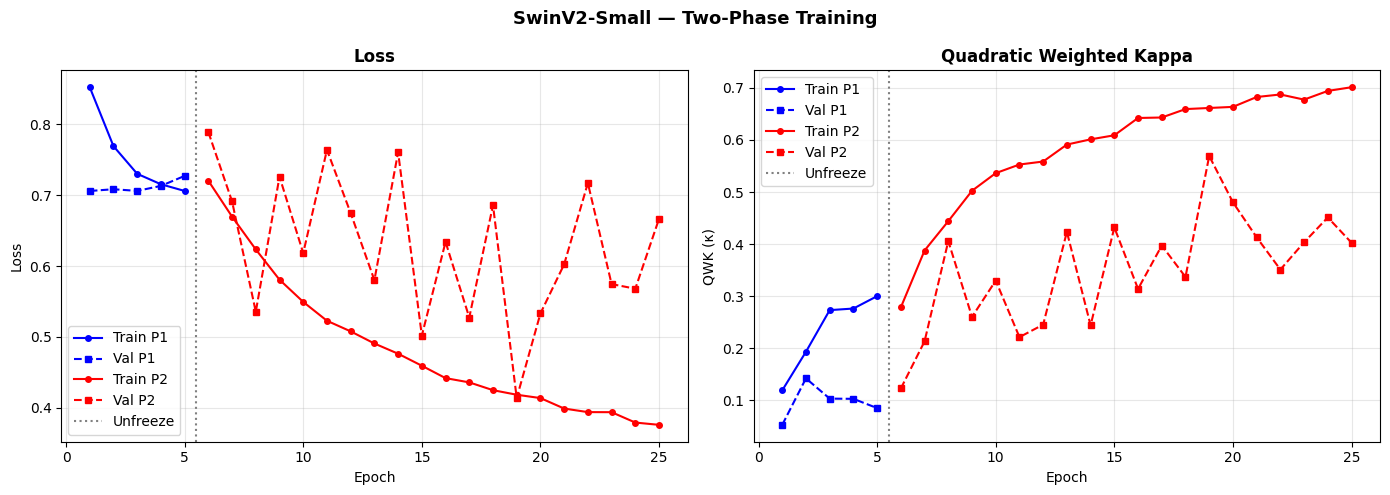

Saved → /scratch/AML_G14_CW/outputs/swinv2_twophase_best/figures/training_curves.png


In [12]:
p1_len = len(history_p1['train_loss'])
p2_len = len(history_p2['train_loss'])
x_p1   = list(range(1, p1_len + 1))
x_p2   = list(range(p1_len + 1, p1_len + p2_len + 1))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('SwinV2-Small — Two-Phase Training', fontsize=13, fontweight='bold')

for ax, p1_tr, p1_vl, p2_tr, p2_vl, ylabel, title in [
    (axes[0],
     history_p1['train_loss'],  history_p1['val_loss'],
     history_p2['train_loss'],  history_p2['val_loss'],
     'Loss', 'Loss'),
    (axes[1],
     history_p1['train_kappa'], history_p1['val_kappa'],
     history_p2['train_kappa'], history_p2['val_kappa'],
     'QWK (κ)', 'Quadratic Weighted Kappa'),
]:
    ax.plot(x_p1, p1_tr, 'b-o',  markersize=4, label='Train P1')
    ax.plot(x_p1, p1_vl, 'b--s', markersize=4, label='Val P1')
    ax.plot(x_p2, p2_tr, 'r-o',  markersize=4, label='Train P2')
    ax.plot(x_p2, p2_vl, 'r--s', markersize=4, label='Val P2')
    ax.axvline(x=p1_len + 0.5, color='gray', linestyle=':', linewidth=1.5, label='Unfreeze')
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel(ylabel)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
fig.savefig(FIG_DIR / 'training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → {FIG_DIR / "training_curves.png"}')

## 11. Evaluation on Test Set

Load the best Phase 2 checkpoint and evaluate on the held-out test set.

Random initialisation.
SwinV2-Small | 49.0M params
Loaded: phase2_best.pt  (epoch 14, val κ=0.5693)


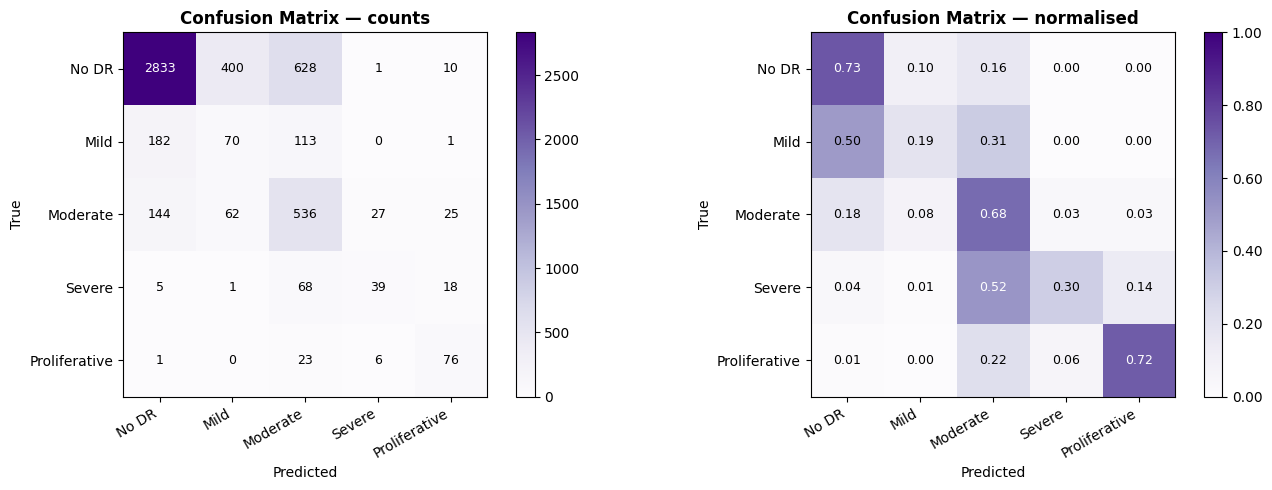

Saved → /scratch/AML_G14_CW/outputs/swinv2_twophase_best/figures/confusion_matrix.png


In [13]:
# ── Load best checkpoint (can run independently after kernel restart) ──────────
model = build_swin_model(pretrained=False).to(device)
ckpt  = torch.load(CKPT_BEST, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Loaded: {CKPT_BEST.name}  (epoch {ckpt["epoch"]}, val κ={ckpt["val_kappa"]:.4f})')

# ── Run on test set ───────────────────────────────────────────────────────────
model.eval()
_, y_true, y_pred, _ = run_epoch(model, test_loader, train_mode=False)

# ── Confusion matrix ──────────────────────────────────────────────────────────
cm = confusion_matrix(y_true, y_pred)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, data, title, fmt, cmap in zip(
    axes,
    [cm, cm.astype(float) / cm.sum(axis=1, keepdims=True)],
    ['Confusion Matrix — counts', 'Confusion Matrix — normalised'],
    ['d', '.2f'],
    ['Purples', 'Purples'],
):
    im = ax.imshow(data, interpolation='nearest', cmap=cmap,
                   vmin=None if fmt == 'd' else 0,
                   vmax=None if fmt == 'd' else 1)
    fig.colorbar(im, ax=ax, format=(None if fmt == 'd' else '%.2f'))
    ax.set_xticks(range(NUM_CLASSES))
    ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
    ax.set_yticks(range(NUM_CLASSES))
    ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(title, fontweight='bold')
    thresh = (data.max() / 2) if fmt == 'd' else 0.5
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, format(data[i, j], fmt), ha='center', va='center',
                    fontsize=9, color='white' if data[i, j] > thresh else 'black')

plt.tight_layout()
fig.savefig(FIG_DIR / 'confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → {FIG_DIR / "confusion_matrix.png"}')

## 12. Results

In [14]:
# ── Overall metrics ───────────────────────────────────────────────────────────
acc      = accuracy_score(y_true, y_pred)
qwk      = cohen_kappa_score(y_true, y_pred, weights='quadratic')
mac_prec = precision_score(y_true, y_pred, average='macro', zero_division=0)
mac_rec  = recall_score(y_true,    y_pred, average='macro', zero_division=0)
mac_f1   = f1_score(y_true,        y_pred, average='macro')

# ── Per-class metrics ─────────────────────────────────────────────────────────
f1_per   = f1_score(y_true,        y_pred, average=None, labels=list(range(5)))
prec_per = precision_score(y_true, y_pred, average=None, labels=list(range(5)), zero_division=0)
rec_per  = recall_score(y_true,    y_pred, average=None, labels=list(range(5)), zero_division=0)

W = 64
print('=' * W)
print('  SwinV2-Small — Two-Phase Training — TEST SET RESULTS')
print('=' * W)
print(f'  QWK (primary metric) : {qwk:.4f}')
print(f'  Accuracy             : {acc:.4f}')
print(f'  Macro Precision      : {mac_prec:.4f}')
print(f'  Macro Recall         : {mac_rec:.4f}')
print(f'  Macro F1             : {mac_f1:.4f}')
print()
print(f'  {"Class":<18} {"Precision":>10} {"Recall":>8} {"F1":>8}')
print('  ' + '─' * 48)
for name, p, r, f in zip(CLASS_NAMES, prec_per, rec_per, f1_per):
    print(f'  {name:<18} {p:>10.4f} {r:>8.4f} {f:>8.4f}')
print('=' * W)

  SwinV2-Small — Two-Phase Training — TEST SET RESULTS
  QWK (primary metric) : 0.5980
  Accuracy             : 0.6745
  Macro Precision      : 0.5074
  Macro Recall         : 0.5225
  Macro F1             : 0.4966

  Class               Precision   Recall       F1
  ────────────────────────────────────────────────
  No DR                  0.8951   0.7317   0.8052
  Mild                   0.1313   0.1913   0.1557
  Moderate               0.3918   0.6751   0.4958
  Severe                 0.5342   0.2977   0.3824
  Proliferative          0.5846   0.7170   0.6441
